In [ ]:
import numpy as np
import rasterio as rio
from rasterio.warp import reproject, Resampling
from matplotlib import pyplot as plt
from pathlib import Path

In [ ]:
ROOT = Path.cwd().parent
DATA = ROOT / "data"
RESULTS = ROOT / "results"

In [ ]:
country_raster_1km_  = rio.open(RESULTS / 'country-rasters' / 'country-raster-eck4-1km.tif')
country_raster_10km_ = rio.open(RESULTS / 'country-rasters' / 'country-raster-eck4-10km.tif')
country_raster_50km_ = rio.open(RESULTS / 'country-rasters' / 'country-raster-eck4-50km.tif')

In [ ]:
PA_Ia_mask_1km  = rio.open(RESULTS / 'protected-area-rasters' / 'protected-area-Ia-mask.tif').read(1)
PA_Ib_mask_1km  = rio.open(RESULTS / 'protected-area-rasters' / 'protected-area-Ib-mask.tif').read(1)
PA_II_mask_1km  = rio.open(RESULTS / 'protected-area-rasters' / 'protected-area-II-mask.tif').read(1)
PA_III_mask_1km = rio.open(RESULTS / 'protected-area-rasters' / 'protected-area-III-mask.tif').read(1)
PA_IV_mask_1km  = rio.open(RESULTS / 'protected-area-rasters' / 'protected-area-IV-mask.tif').read(1)
PA_V_mask_1km   = rio.open(RESULTS / 'protected-area-rasters' / 'protected-area-V-mask.tif').read(1)
PA_VI_mask_1km  = rio.open(RESULTS / 'protected-area-rasters' / 'protected-area-VI-mask.tif').read(1)
water_mask_1km  = rio.open(RESULTS / 'mining-area' / 'global-water-area-1km.tif').read(1)

In [ ]:
urban_area_1km    = rio.open(RESULTS / 'features' / 'urban-area-2020-1km.tif').read(1)
forest_area_1km   = rio.open(RESULTS / 'features' / 'forest' / 'forest-2020-1km.tif').read(1)
cropland_area_1km = rio.open(RESULTS / 'features' / 'cropland-2019-1km.tif').read(1)
mining_area_1km   = rio.open(RESULTS / 'quarry-area-rasters' / 'global-quarry-area-raster-eck4-1km.tif').read(1)

In [ ]:
cropland_area_1km = np.clip(cropland_area_1km, 0, 100)

In [25]:
PA_mask_BAU = np.clip(
    PA_Ia_mask_1km + PA_Ib_mask_1km + PA_II_mask_1km + PA_III_mask_1km + PA_IV_mask_1km,
    0, 1
)

In [44]:
PA_mask_CON = np.clip(
    PA_Ia_mask_1km + PA_Ib_mask_1km + PA_II_mask_1km + PA_III_mask_1km + PA_IV_mask_1km + PA_V_mask_1km + PA_VI_mask_1km,
    0, 1
)

In [33]:
available_area_BAU_1km = (
    (1 - urban_area_1km / 100) *
    (1 - mining_area_1km) *
    (1 - water_mask_1km)
    # * (1 - forest_area_1km) * (1 - cropland_area_1km)   # <- 若想扣林地和耕地可取消注释
).astype(np.float32)

In [ ]:
available_area_BAU_1km[PA_mask_BAU == 1] = 0
available_area_BAU_1km[country_raster_1km == 0] = 0

In [48]:
available_area_CON_1km = (
    (1 - urban_area_1km / 100) *
    (1 - mining_area_1km) *
    (1 - water_mask_1km)
    * (1 - forest_area_1km / 100) * (1 - cropland_area_1km / 100)   # <- 若想扣林地和耕地可取消注释
).astype(np.float32)

In [ ]:
available_area_CON_1km[PA_mask_CON == 1] = 0
available_area_CON_1km[country_raster_1km == 0] = 0

In [ ]:
with rio.open(
    RESULTS / 'mining-area' / 'available-area-BAU-1km.tif',
    "w",
    driver="GTiff",
    height=country_raster_1km_.shape[0],
    width=country_raster_1km_.shape[1],
    count=1,
    dtype=available_area_BAU_1km.dtype,
    crs=country_raster_1km_.crs,
    transform=country_raster_1km_.transform,
    compress='lzw'
) as dst:
    dst.write(available_area_BAU_1km, 1)

In [ ]:
with rio.open(
    RESULTS / 'mining-area' / 'available-area-CON-1km.tif',
    "w",
    driver="GTiff",
    height=country_raster_1km_.shape[0],
    width=country_raster_1km_.shape[1],
    count=1,
    dtype=available_area_CON_1km.dtype,
    crs=country_raster_1km_.crs,
    transform=country_raster_1km_.transform,
    compress='lzw'
) as dst:
    dst.write(available_area_CON_1km, 1)

reproject available area

In [ ]:
available_area_BAU_1km = rio.open(RESULTS / 'mining-area' / 'available-area-BAU-1km.tif').read(1)
available_area_CON_1km = rio.open(RESULTS / 'mining-area' / 'available-area-CON-1km.tif').read(1)

In [6]:
available_area_BAU_50km = np.zeros(country_raster_50km_.shape, dtype=np.float32)
reproject(
    source=available_area_BAU_1km,
    destination=available_area_BAU_50km,
    src_transform=country_raster_1km_.transform,
    src_crs=country_raster_1km_.crs,
    dst_transform=country_raster_50km_.transform,
    dst_crs=country_raster_50km_.crs,
    resampling=Resampling.sum  # 你也可以用 Resampling.nearest
)

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], shape=(340, 678), dtype=float32),
 Affine(50000.0, 0.0, -16950000.0,
        0.0, -50000.0, 8500000.0))

In [7]:
available_area_CON_50km = np.zeros(country_raster_50km_.shape, dtype=np.float32)
reproject(
    source=available_area_CON_1km,
    destination=available_area_CON_50km,
    src_transform=country_raster_1km_.transform,
    src_crs=country_raster_1km_.crs,
    dst_transform=country_raster_50km_.transform,
    dst_crs=country_raster_50km_.crs,
    resampling=Resampling.sum  # 你也可以用 Resampling.nearest
)

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], shape=(340, 678), dtype=float32),
 Affine(50000.0, 0.0, -16950000.0,
        0.0, -50000.0, 8500000.0))

In [15]:
available_area_BAU_50km = np.clip(available_area_BAU_50km, 0, 2500)
available_area_CON_50km = np.clip(available_area_CON_50km, 0, 2500)

In [14]:
np.min(available_area_BAU_50km)

np.float32(0.0)

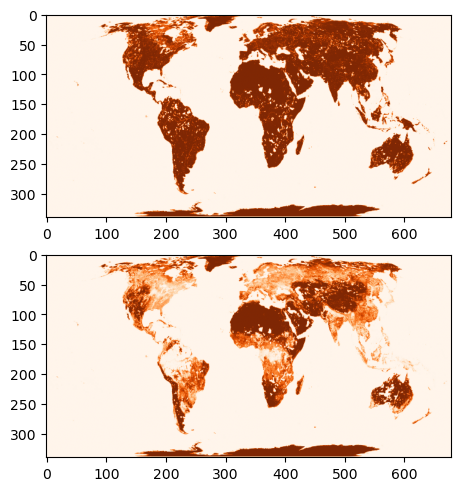

In [21]:
fig = plt.figure(constrained_layout=True)
plt.subplot(211), plt.imshow(available_area_BAU_50km, vmin=0, vmax=2500, cmap='Oranges')
plt.subplot(212), plt.imshow(available_area_CON_50km, vmin=0, vmax=2500, cmap='Oranges')
plt.show()

In [ ]:
with rio.open(
    RESULTS / 'mining-area' / 'available-area-BAU-50km.tif',
    "w",
    driver="GTiff",
    height=country_raster_50km_.shape[0],
    width=country_raster_50km_.shape[1],
    count=1,
    dtype=available_area_BAU_50km.dtype,
    crs=country_raster_50km_.crs,
    transform=country_raster_50km_.transform,
    compress='lzw'
) as dst:
    dst.write(available_area_BAU_50km, 1)

In [ ]:
with rio.open(
    RESULTS / 'mining-area' / 'available-area-CON-50km.tif',
    "w",
    driver="GTiff",
    height=country_raster_50km_.shape[0],
    width=country_raster_50km_.shape[1],
    count=1,
    dtype=available_area_CON_50km.dtype,
    crs=country_raster_50km_.crs,
    transform=country_raster_50km_.transform,
    compress='lzw'
) as dst:
    dst.write(available_area_CON_50km, 1)

In [ ]:
mining_suitability_1km = rio.open(RESULTS / 'mining-suitability' / 'global-mining-suitability.tif').read(1)

In [26]:
mining_suitability_1km = (np.nan_to_num(mining_suitability_1km) * 1e4).astype(np.uint16)

In [27]:
mining_suitability_1km

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(16922, 33844), dtype=uint16)

In [ ]:
with rio.open(
    RESULTS / 'mining-suitability' / 'global-mining-suitability-1km.tif',
    "w",
    driver="GTiff",
    height=country_raster_1km_.shape[0],
    width=country_raster_1km_.shape[1],
    count=1,
    dtype=mining_suitability_1km.dtype,
    crs=country_raster_1km_.crs,
    transform=country_raster_1km_.transform,
    compress='lzw'
) as dst:
    dst.write(mining_suitability_1km, 1)